# Fine-tuning de Qwen3.5-4B con QLoRA

Ajuste fino del LLM del chatbot de Kalish Manta Analytics, un asistente que orienta a investigadores en el acceso a bases de datos de economía y ciencias sociales del Perú. El modelo aprende el rol, el tono y el comportamiento del asistente (saludos, solicitudes completas o incompletas, preguntas fuera de alcance, perfiles junior y senior) y a responder solo con las fichas de bases de datos que le entrega el sistema RAG.

Entrenado en una GPU NVIDIA RTX 5050 Laptop (8GB de VRAM, arquitectura Blackwell) con Windows.

Flujo del notebook:

1. Datos: carga y separación en train, validation y test.
2. Carga del modelo base cuantizado en 4 bits.
3. Preguntas de control antes del entrenamiento.
4. Formato de las conversaciones con la plantilla de chat.
5. Ronda A: hiperparámetros (3 y 6 épocas).
6. Ronda B: capas donde se insertan las matrices LoRA.
7. Evaluación del mejor modelo en test.
8. Comparación cualitativa antes y después del fine-tuning.
9. Guardado del modelo mergeado para el RAG.

In [1]:
# Paso 0. PyTorch para GPUs Blackwell (RTX 50xx, sm_120).
# Blackwell necesita PyTorch 2.7 o superior compilado con CUDA 12.8 o superior; se usa
# el índice de ruedas cu130, el mismo que documenta Unsloth para Windows.
#
# Va en su propia celda y antes de Unsloth, para que una instalación posterior no
# reemplace torch por una versión sin soporte para sm_120.
# Las instalaciones están comentadas: descomentarlas solo la primera vez.


#!pip install --upgrade torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu130

In [2]:
# En Linux (por ejemplo Colab) unsloth resuelve sus dependencias sin problema. En
# Windows con una GPU Blackwell, si pip resuelve todo junto puede reemplazar el torch
# cu130 del paso anterior; por eso unsloth y unsloth_zoo se instalan con --no-deps.

# Paso 1. Triton para Windows. El paquete oficial triton no publica ruedas para Windows
# y sin este fork Unsloth no puede usar sus kernels optimizados. Blackwell necesita
# Triton 3.3 o superior; pip elige la versión compatible con el torch instalado.

#!pip install --upgrade triton-windows

# Paso 2. bitsandbytes 0.43.3 o superior, el mínimo que documenta Unsloth. Una versión
# anterior se instala sin errores pero falla al cuantizar en 4 bits.

#!pip install --upgrade "bitsandbytes>=0.43.3"

# Paso 3. Unsloth con --no-deps para que no reinstale ni cambie la versión de torch.

#!pip install --upgrade --no-cache-dir --no-deps unsloth unsloth_zoo

# Paso 4. Dependencias que --no-deps omitió. xformers queda fuera a propósito: en
# Windows con Blackwell hay que compilarlo desde el código fuente y no es obligatorio,
# porque Unsloth usa la atención sdpa de PyTorch si no lo encuentra.

#!pip install --upgrade --no-cache-dir transformers trl peft accelerate

In [3]:
import gc
import json
import os
import random

# Unsloth divide en partes (chunking) la cross-entropy fusionada según la memoria libre
# que reporta el driver (torch.cuda.mem_get_info). En una GPU de 8GB con Windows (WDDM)
# ese valor puede leerse cercano a cero en el primer paso de entrenamiento, por las
# reservas del allocator, y Unsloth aborta en lugar de dividir en partes más pequeñas.
# Un presupuesto pequeño pero positivo hace que siempre divida: cada paso es algo más
# lento, pero el entrenamiento no se interrumpe. Debe definirse antes del primer import
# de unsloth para que la variable de entorno se lea a tiempo.

os.environ["UNSLOTH_CE_LOSS_TARGET_GB"] = "0.2"

import torch
from unsloth import is_bfloat16_supported

# Verificación de la GPU disponible
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name)
    print("VRAM total (GB):", round(props.total_memory / 1e9, 2))
    print("Esta GPU soporta bf16:", is_bfloat16_supported())
else:
    raise RuntimeError("No hay GPU disponible")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


c:\Users\USER\Dropbox\Personal_Desktop2026\RepositoryGitHub\RAGCentralDatabaseEconomy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🦥 Unsloth Zoo will now patch everything to make training faster!
CUDA disponible: True
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
VRAM total (GB): 8.55
Esta GPU soporta bf16: True


## Configuración

Las rutas, el modelo, el rango de LoRA (`r`), `LORA_DROPOUT` y `LEARNING_RATE` son fijos. Lo que cambia entre experimentos (épocas, batch efectivo, alpha, warmup, weight decay y capas con LoRA) se define en las celdas de las rondas A y B.

El dataset combina conversaciones originales sin system prompt y conversaciones en el formato exacto de producción: system prompt con el catálogo, las reglas y las fichas recuperadas por el RAG (generadas con `src/construir_dataset_rag.py`).

In [4]:
# Dataset de conversaciones para el fine-tuning y dossier del asistente (propósito,
# reglas y catálogo de bases), que sirve de referencia para las preguntas de control
RUTA_DATASET = "../data/Finetuning/dataset_EconData.jsonl"
RUTA_DOSSIER = "../data/Finetuning/dataset_EconData.md"

# Modelo instruct base, en la versión publicada por Unsloth en Hugging Face
MODELO_INSTRUCT = "unsloth/Qwen3.5-4B"

# Las conversaciones con fichas del RAG llegan a 2459 tokens. Medido en la RTX 5050:
# con LoRA en todas las capas y secuencias de ese largo, el pico de VRAM es 4.8GB.
MAX_SEQ_LENGTH = 2560
LOAD_IN_4BIT = True  # QLoRA: el modelo base queda congelado y cuantizado a 4 bits;
                      # los adaptadores LoRA se entrenan aparte, siempre en 16 bits

# Hiperparámetros fijos en todos los experimentos. El rango r es fijo porque los
# adaptadores LoRA se insertan una sola vez (ver sección 5).
R_LORA = 16
LORA_DROPOUT = 0.05
LEARNING_RATE = 4e-4

# Semilla fija para que la separación de datos y el entrenamiento sean reproducibles
SEMILLA = 3407
random.seed(SEMILLA)

# En True reduce el dataset a unos pocos ejemplos, útil para comprobar que todo el
# pipeline corre de punta a punta antes de lanzar la ronda completa de experimentos.
MODO_RAPIDO = False

## 1. Datos: carga y separación en train, validation y test

Cada ejemplo es una conversación entre usuario y asistente, etiquetada con una categoría de comportamiento: saludo, solicitud completa, falta de información, pregunta fuera de alcance, base no disponible, perfil junior o senior, entre otras.

In [5]:
# Carga del dataset en formato JSONL y conteo de conversaciones por categoría
from datasets import load_dataset
from collections import Counter

dataset_crudo = load_dataset("json", data_files=RUTA_DATASET, split="train")

print("Conversaciones totales:", len(dataset_crudo))
print("Por categoría:")
for categoria, cantidad in Counter(dataset_crudo["categoria"]).most_common():
    print(f"  {categoria}: {cantidad}")

Conversaciones totales: 567
Por categoría:
  solicitud: 146
  fuera_de_alcance: 70
  junior_guiado: 65
  falta_informacion: 49
  saludo_presentacion: 36
  senior_riguroso: 36
  base_no_disponible: 36
  saludo: 25
  despedida: 24
  limite_revisiones: 22
  catalogo: 16
  solicitud_completa: 14
  dos_temas: 11
  dos_bases: 9
  multiturno: 8


In [6]:
# Separación aleatoria 80% train, 10% validation y 10% test, con semilla fija para
# que sea reproducible.

split_1 = dataset_crudo.train_test_split(test_size=0.20, seed=SEMILLA)

dataset_train = split_1["train"]

split_2 = split_1["test"].train_test_split(test_size=0.50, seed=SEMILLA)
dataset_val = split_2["train"]
dataset_test = split_2["test"]

print("Train:", len(dataset_train))
print("Validation:", len(dataset_val))
print("Test:", len(dataset_test))

# Subconjunto pequeño para una corrida de prueba
if MODO_RAPIDO:
    dataset_train = dataset_train.select(range(min(40, len(dataset_train))))
    dataset_val = dataset_val.select(range(min(15, len(dataset_val))))
    print("MODO_RAPIDO activo, usando solo:", len(dataset_train), "train /", len(dataset_val), "val")

Train: 453
Validation: 57
Test: 57


In [7]:
# El dossier no se usa para entrenar. Es la referencia para revisar las respuestas a
# las preguntas de control (propósito del asistente, catálogo de bases y reglas).

with open(RUTA_DOSSIER, encoding="utf-8") as f:
    dossier = f.read()

print("Dossier cargado,", len(dossier.splitlines()), "líneas")

Dossier cargado, 145 líneas


## 2. Cargar el modelo con QLoRA

Con `load_in_4bit=True` los pesos del modelo base quedan cuantizados en 4 bits y congelados: no cambian durante el entrenamiento. Sobre ellos se insertan después los adaptadores LoRA, que son los únicos parámetros que se entrenan.

El modelo se carga una sola vez en todo el notebook: se usa para las respuestas de referencia de la sección 3 y, con los adaptadores LoRA, para los experimentos de la sección 5.

In [8]:
# Modelo base: única carga del notebook. Se usa para las respuestas de referencia
# y después, con los adaptadores LoRA, para entrenar
from unsloth import FastLanguageModel

modelo_base, tokenizer_base = FastLanguageModel.from_pretrained(
    model_name=MODELO_INSTRUCT,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=LOAD_IN_4BIT,
    full_finetuning=False,
)
# Modo inferencia de Unsloth, con generación más rápida
FastLanguageModel.for_inference(modelo_base)

print("Modelo cargado:", round(modelo_base.num_parameters() / 1e9, 2), "B parámetros")

==((====))==  Unsloth 2026.10.6: Fast Qwen3_5 patching. Transformers: 5.20.1.
   \\   /|    NVIDIA GeForce RTX 5050 Laptop GPU. Num GPUs = 1. Max memory: 7.96 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 12.0. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth


Loading weights: 100%|██████████| 723/723 [00:10<00:00, 72.11it/s] 
c:\Users\USER\Dropbox\Personal_Desktop2026\RepositoryGitHub\RAGCentralDatabaseEconomy\.venv\Lib\site-packages\transformers\models\qwen2_vl\image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Unsloth: compiling each transformer block as one region (Qwen3_5DecoderLayer).
Modelo cargado: 4.54 B parámetros


In [9]:
from contextlib import nullcontext


def plantilla_chat(tokenizer, mensajes, add_generation_prompt=True):
    """Aplica la plantilla de chat de Qwen3.5 en modo no thinking, la misma en
    entrenamiento e inferencia."""
    return tokenizer.apply_chat_template(
        mensajes, tokenize=False, add_generation_prompt=add_generation_prompt,
        enable_thinking=False,
    )


def responder(modelo, tokenizer, pregunta, con_lora=True, max_new_tokens=300):
    """Genera una respuesta del asistente para una pregunta.

    Con con_lora=False se desactivan los adaptadores con disable_adapter() de PEFT, sin
    recargar el modelo, para comparar contra exactamente el mismo modelo base.

    La temperatura (0.2) y la penalización por repetición (1.2) son bajas a propósito:
    el asistente debe ser consistente y fiel a los datos, sin variar la respuesta cada
    vez que se le hace la misma pregunta.
    """
    prompt = plantilla_chat(tokenizer, [{"role": "user", "content": pregunta}])
    inputs = tokenizer(text=[prompt], return_tensors="pt").to("cuda")

    if con_lora or not hasattr(modelo, "disable_adapter"):
        contexto = nullcontext()
    else:
        contexto = modelo.disable_adapter()

    with contexto:
        salida = modelo.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=0.2,
            repetition_penalty=1.2,
            top_p=0.9,
            use_cache=True,
        )
    # Se decodifican solo los tokens nuevos, sin el prompt
    return tokenizer.decode(salida[0][inputs.input_ids.shape[1]:], skip_special_tokens=True)

## 3. Preguntas de control

Dos grupos de preguntas para comparar el modelo antes y después del fine-tuning. Las preguntas de investigación evalúan si aprendió el rol del asistente. Las preguntas de control quedan fuera de lo que vio en el entrenamiento y sirven para detectar olvido catastrófico o sobreajuste de tono.

In [10]:
# Preguntas sobre el rol del asistente, cubiertas por el dataset
PREGUNTA_PROPOSITO = "Qué es lo que puedes hacer para ayudarme en mi tesis?"
PREGUNTA_BASES = "Qué bases de datos tienes disponibles?"

# Preguntas fuera de lo que el modelo vio en el dataset de entrenamiento
PREGUNTA_ACADEMICO = "Cómo estimar un modelo de diferencias en diferencias de econometría para mi tesis"
PREGUNTA_CONOCIMIENTO_GENERAL = "Explícame en dos líneas qué son la Teoría de Juegos y la Organización Industrial"

PREGUNTAS_INVESTIGACION = [PREGUNTA_PROPOSITO, PREGUNTA_BASES]
PREGUNTAS_CONTROL = [PREGUNTA_ACADEMICO, PREGUNTA_CONOCIMIENTO_GENERAL]

In [11]:
# Respuestas del modelo instruct antes del fine-tuning, como línea base para comparar
# más adelante.

respuestas_base = {}
for pregunta in PREGUNTAS_INVESTIGACION + PREGUNTAS_CONTROL:
    respuestas_base[pregunta] = responder(modelo_base, tokenizer_base, pregunta, con_lora=False)
    print("PREGUNTA:", pregunta)
    print("RESPUESTA:", respuestas_base[pregunta])
    print()

`causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
`causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


PREGUNTA: Qué es lo que puedes hacer para ayudarme en mi tesis?
RESPUESTA: ¡Excelente pregunta! Como modelo de inteligencia artificial, puedo actuar como un **asistente virtual 24/7** a través del ciclo completo de tu investigación. Aunque no puedo realizar experimentos físicos ni acceder a bases de datos pagadas sin conexión, tengo capacidades muy potentes en las siguientes áreas:

### 📚 Investigación y Búsqueda de Información
*   **Definición de conceptos:** Puedo explicarte términos complejos o ayudarte a encontrar la definición precisa de variables clave.
*   **Breves resúmenes:** Si me das el título de una teoría o autor relevante (si ya tienes acceso al texto), puedo resumir sus puntos principales.
*   **Análisis literario:** Puedo leer textos académicos que subas y extraer citas relevantes, identificar tendencias metodológicas o comparar diferentes enfoques teóricos.

### ✍️ Estructura y Planificación
*   **Diseño de la propuesta:** Ayudamos a crear un índice lógico, definir obj

## 4. Formatear las conversaciones para entrenamiento

Se aplica la plantilla de chat de Qwen3.5 a cada conversación, sin agregar el inicio de una respuesta nueva (`add_generation_prompt=False`), para que el texto quede tal cual lo verá el modelo durante el entrenamiento.

In [12]:
# Convierte cada lote de conversaciones en una columna "text" con la plantilla aplicada
def formatear_conversaciones(tokenizer):
    def _mapear(examples):
        return {"text": [
            plantilla_chat(tokenizer, conv, add_generation_prompt=False)
            for conv in examples["conversations"]
        ]}
    return _mapear


# Aplica el formato a un split y deja solo la columna "text", la que usa SFTTrainer
def preparar_split(dataset_split, tokenizer):
    formateado = dataset_split.map(formatear_conversaciones(tokenizer), batched=True)
    columnas_sobrantes = [c for c in formateado.column_names if c != "text"]
    return formateado.remove_columns(columnas_sobrantes)


dataset_train_texto = preparar_split(dataset_train, tokenizer_base)
dataset_val_texto = preparar_split(dataset_val, tokenizer_base)
dataset_test_texto = preparar_split(dataset_test, tokenizer_base)

# Ejemplo del texto formateado
print(dataset_train_texto[0]["text"][:500])

<|im_start|>system
Eres el asistente de Kalish Manta Analytics. Guías a investigadores, desde estudiantes hasta académicos, en la búsqueda eficiente de bases de datos de economía y ciencias sociales del Perú a partir de sus propuestas o ideas de investigación.

Bases de datos disponibles en el catálogo:
Cartografía, clima e infraestructura (shapefiles): Fenómeno El Niño en el Perú: anomalías de precipitación 1982-1983, 1997-1998 y 2017; Shapefile de la red vial del Perú 2018: nacional, departame


## 5. Diseño experimental, ronda A (hiperparámetros)

Dos configuraciones con LoRA solo en las capas de atención:

| | 3 épocas | 6 épocas |
|---|---|---|
| Batch efectivo | 8 | 16 |
| `lora_alpha` | 16 | 32 |
| Warmup | 10 pasos | 20 pasos |
| Weight decay | 0.01 | 0.1 |

Con batch efectivo 16, la configuración de 6 épocas da el mismo número de pasos de optimización que la de 3 épocas con batch 8: ve cada ejemplo el doble de veces con gradientes más estables, más regularización (weight decay) y una actualización de LoRA más fuerte (alpha 32, es decir, escala alpha/r de 2).

**Una sola carga del modelo.** En 8GB de VRAM no cabe una copia nueva del modelo por experimento, porque parte de la memoria de cada carga no se libera entre corridas. Por eso el modelo de la sección 2 se reutiliza: los adaptadores LoRA se insertan una sola vez en todas las capas lineales y se guarda una copia de sus pesos iniciales. Antes de cada experimento:

1. Se restauran los pesos LoRA iniciales, como si el modelo se cargara de cero.
2. Se activan (`requires_grad`) solo los adaptadores de las capas de esa configuración; los demás quedan congelados con su matriz B en cero, así que no modifican el modelo.
3. Se fija la escala alpha/r de esa configuración.

Al final de cada ronda, el modelo queda con los pesos LoRA del mejor experimento.

In [13]:
# Módulos del transformer donde se pueden insertar adaptadores LoRA. Qwen3.5 es
# híbrido: 8 de sus 32 capas tienen atención completa (q, k, v, o) y 24 tienen
# atención lineal (in_proj_qkv, in_proj_z, out_proj); todas tienen MLP.
ATENCION = ["q_proj", "k_proj", "v_proj", "o_proj"]
ATENCION_LINEAL = ["in_proj_qkv", "in_proj_z", "out_proj"]
MLP = ["gate_proj", "up_proj", "down_proj"]
TODAS_LAS_CAPAS = ATENCION + ATENCION_LINEAL + MLP

# per_device_batch es 1 porque en 8GB de VRAM es lo que más pesa en memoria de
# activaciones; grad_accum fija el batch efectivo (per_device_batch por grad_accum).
configs_ronda_a = [
    {
        "nombre": "3_epocas",
        "epochs": 2,
        "per_device_batch": 1,
        "grad_accum": 8,
        "lora_alpha": 16,
        "warmup_steps": 10,
        "weight_decay": 0.01,
        "target_modules": ATENCION,
    },
    {
        "nombre": "6_epocas",
        "epochs": 4,
        "per_device_batch": 1,
        "grad_accum": 16,
        "lora_alpha": 32,
        "warmup_steps": 10,
        "weight_decay": 0.1,
        "target_modules": ATENCION,
    },
]

# En modo rápido: una época por configuración
if MODO_RAPIDO:
    for c in configs_ronda_a:
        c["epochs"] = 1

for c in configs_ronda_a:
    print(c["nombre"], "->", {k: v for k, v in c.items() if k not in ("nombre", "target_modules")})

3_epocas -> {'epochs': 2, 'per_device_batch': 1, 'grad_accum': 8, 'lora_alpha': 16, 'warmup_steps': 10, 'weight_decay': 0.01}
6_epocas -> {'epochs': 4, 'per_device_batch': 1, 'grad_accum': 16, 'lora_alpha': 32, 'warmup_steps': 10, 'weight_decay': 0.1}


In [14]:
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only

# Adaptadores LoRA en todas las capas lineales del modelo de la sección 2, una sola
# vez. Cada experimento activa solo los de sus capas (activar_lora). La torre de
# visión de Qwen3.5 queda fuera. El gradient checkpointing de Unsloth recalcula
# activaciones en el backward para ahorrar VRAM.
modelo = FastLanguageModel.get_peft_model(
    modelo_base,
    r=R_LORA,
    target_modules=TODAS_LAS_CAPAS,
    lora_alpha=R_LORA,
    lora_dropout=LORA_DROPOUT,
    bias="none",
    finetune_vision_layers=False,
    use_gradient_checkpointing="unsloth",
    random_state=SEMILLA,
    max_seq_length=MAX_SEQ_LENGTH,
)
tokenizer = tokenizer_base

# Precisión mixta según el tipo de los pesos y el soporte de la GPU
dtype_pesos = next(modelo.parameters()).dtype
usar_bf16 = (dtype_pesos == torch.bfloat16) and is_bfloat16_supported()
usar_fp16 = (dtype_pesos == torch.float16)


def pesos_lora(modelo):
    """Copia en CPU de los pesos LoRA, sin los pesos del modelo base"""
    return {n: p.detach().to("cpu", copy=True) for n, p in modelo.named_parameters() if "lora_" in n}


def cargar_pesos_lora(modelo, pesos):
    """Sobrescribe los pesos LoRA del modelo con una copia guardada"""
    with torch.no_grad():
        for n, p in modelo.named_parameters():
            if n in pesos:
                p.copy_(pesos[n].to(p.device))


def configurar_lora(modelo, config):
    """Activa solo los adaptadores de las capas de la configuración y fija su escala.

    Los adaptadores de las demás capas quedan congelados; como parten de los pesos
    iniciales (matriz B en cero), no modifican la salida del modelo. Devuelve el
    número de parámetros entrenables.
    """
    entrenables = 0
    for nombre, p in modelo.named_parameters():
        if "lora_" in nombre:
            activo = any(f".{m}." in nombre for m in config["target_modules"])
            p.requires_grad_(activo)
            entrenables += p.numel() if activo else 0
    # La escala de LoRA es alpha / r; Unsloth la lee de cada capa en cada paso
    for modulo in modelo.modules():
        if isinstance(getattr(modulo, "scaling", None), dict) and "default" in modulo.scaling:
            modulo.scaling["default"] = config["lora_alpha"] / R_LORA
    return entrenables


# Pesos LoRA recién inicializados: todos los experimentos parten de esta copia
PESOS_LORA_INICIALES = pesos_lora(modelo)
print("Parámetros LoRA insertados:", sum(p.numel() for p in PESOS_LORA_INICIALES.values()))


def crear_trainer(config, dataset_train_texto, dataset_eval_texto, tag=""):
    """SFTTrainer para el modelo con LoRA según la configuración dada"""
    trainer = SFTTrainer(
        model=modelo,
        tokenizer=tokenizer,
        train_dataset=dataset_train_texto,
        eval_dataset=dataset_eval_texto,
        args=SFTConfig(
            max_seq_length=MAX_SEQ_LENGTH,
            per_device_train_batch_size=config["per_device_batch"],
            per_device_eval_batch_size=config["per_device_batch"],
            gradient_accumulation_steps=config["grad_accum"],
            warmup_steps=config["warmup_steps"],
            num_train_epochs=config["epochs"],
            learning_rate=LEARNING_RATE,
            logging_steps=1,
            eval_strategy="epoch",
            optim="adamw_8bit",
            weight_decay=config["weight_decay"],
            lr_scheduler_type="linear",
            seed=SEMILLA,
            output_dir=f"outputs_{config['nombre']}{tag}",
            # Sin checkpoints intermedios: no se usan (el modelo final se guarda al
            # final del notebook) y, dentro de una carpeta sincronizada por Dropbox,
            # provocan errores intermitentes (OSError: [Errno 22] Invalid argument)
            # porque Dropbox bloquea los archivos cuando el Trainer intenta renombrarlos.
            save_strategy="no",
            report_to="none",
            bf16=usar_bf16,
            fp16=usar_fp16,
            dataset_num_proc=1,
        ),
    )

    # El loss se calcula solo sobre las respuestas del asistente: el modelo aprende a
    # responder, no a imitar los mensajes del usuario ni el system prompt
    return train_on_responses_only(
        trainer,
        instruction_part="<|im_start|>user\n",
        response_part="<|im_start|>assistant\n",
    )


def entrenar_config(config, dataset_train_texto, dataset_val_texto, tag=""):
    """Entrena los adaptadores LoRA de la configuración, partiendo de los pesos LoRA
    iniciales, y devuelve el historial de loss. Restaurar los pesos iniciales equivale
    a empezar con un modelo recién cargado, sin cargar otra copia en la GPU.
    """
    cargar_pesos_lora(modelo, PESOS_LORA_INICIALES)
    entrenables = configurar_lora(modelo, config)
    print(f"  parámetros entrenables: {entrenables:,}")
    FastLanguageModel.for_training(modelo)

    trainer = crear_trainer(config, dataset_train_texto, dataset_val_texto, tag)
    resultado = trainer.train()

    # Historial de loss de train y de validation para graficar y comparar
    historial_train = [h for h in trainer.state.log_history if "loss" in h and "eval_loss" not in h]
    historial_eval = [h for h in trainer.state.log_history if "eval_loss" in h]

    # Libera el optimizer y los buffers del trainer; el modelo se mantiene en la GPU.
    # accelerate guarda un singleton que retiene referencias a cada Trainer creado.
    try:
        trainer.accelerator.free_memory()
    except Exception:
        pass
    del trainer
    try:
        from accelerate.state import AcceleratorState
        AcceleratorState._reset_state()
    except Exception:
        pass
    gc.collect()
    torch.cuda.empty_cache()

    return {
        "config": config,
        "entrenables": entrenables,
        "train_loss": [h["loss"] for h in historial_train],
        "train_steps": [h["step"] for h in historial_train],
        "eval_loss": [h["eval_loss"] for h in historial_eval],
        "eval_epoch": [h["epoch"] for h in historial_eval],
        "tiempo_seg": resultado.metrics["train_runtime"],
        "eval_loss_final": historial_eval[-1]["eval_loss"] if historial_eval else None,
    }

Unsloth: Explicit target_modules are constrained by the finetune_(vision|language|attention|mlp) filters; adapters attach only where both select.


Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.05.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.


Parámetros LoRA insertados: 30474240


In [15]:
# Entrena cada configuración desde los mismos pesos LoRA iniciales y guarda en CPU
# una copia de los pesos del mejor experimento según validation loss
resultados_ronda_a = {}
mejor_resultado = None
mejores_pesos = None

for config in configs_ronda_a:
    print("Entrenando configuración:", config["nombre"])
    resultado = entrenar_config(config, dataset_train_texto, dataset_val_texto)
    print(f"  tiempo: {resultado['tiempo_seg']:.1f}s, eval_loss final: {resultado['eval_loss_final']:.4f}")
    resultados_ronda_a[config["nombre"]] = resultado

    if mejor_resultado is None or resultado["eval_loss_final"] < mejor_resultado["eval_loss_final"]:
        mejor_resultado = resultado
        mejores_pesos = pesos_lora(modelo)

# El modelo queda con los pesos LoRA del mejor experimento y su configuración
cargar_pesos_lora(modelo, mejores_pesos)
configurar_lora(modelo, mejor_resultado["config"])
print("Mejor configuración de la ronda A:", mejor_resultado["config"]["nombre"])

[unsloth.hybrid_packing|WARNING]Unsloth: hybrid linear-attention packing disabled (padded path): exactness probe failed to run (ValueError: `causal_conv1d_fn` can't keep packed sequences apart without `causal_conv1d`. Install `causal_conv1d` to train on packed sequences.).


Entrenando configuración: 3_epocas
  parámetros entrenables: 3,145,728


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 453 | Num Epochs = 2 | Total steps = 114
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 3,145,728 of 4,569,739,776 (0.07% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Epoch,Training Loss,Validation Loss
1,0.767312,1.055686
2,0.528554,0.880202


...

  tiempo: 2175.5s, eval_loss final: 0.8802
Entrenando configuración: 6_epocas
  parámetros entrenables: 3,145,728


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 453 | Num Epochs = 4 | Total steps = 116
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 3,145,728 of 4,569,739,776 (0.07% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Epoch,Training Loss,Validation Loss
1,0.873047,1.178880
2,0.491900,0.845562
3,0.511492,0.742038
4,0.278583,0.724826


  tiempo: 4039.7s, eval_loss final: 0.7248
Mejor configuración de la ronda A: 6_epocas


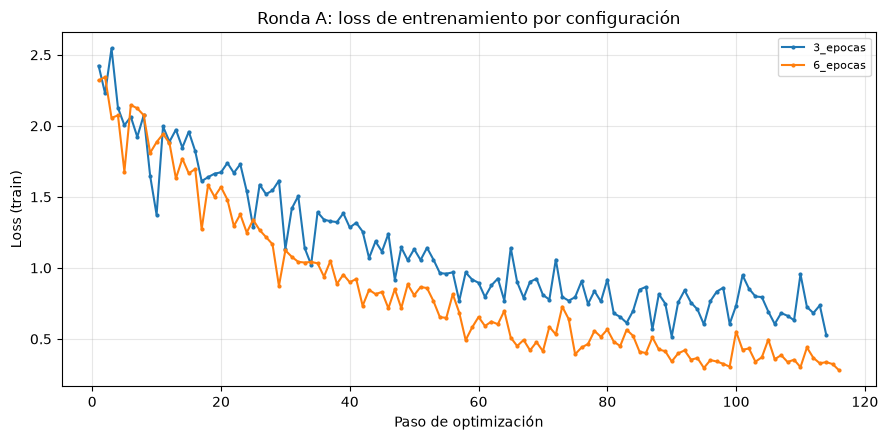

In [16]:
# Curvas de loss de entrenamiento de la ronda A
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4.5))
for nombre, r in resultados_ronda_a.items():
    plt.plot(r["train_steps"], r["train_loss"], marker="o", markersize=2, label=nombre)
plt.xlabel("Paso de optimización")
plt.ylabel("Loss (train)")
plt.title("Ronda A: loss de entrenamiento por configuración")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# Tabla comparativa de la ronda A ordenada por validation loss
import pandas as pd

tabla_ronda_a = pd.DataFrame([
    {
        "configuracion": nombre,
        "epochs": r["config"]["epochs"],
        "batch_efectivo": r["config"]["per_device_batch"] * r["config"]["grad_accum"],
        "lora_alpha": r["config"]["lora_alpha"],
        "warmup_steps": r["config"]["warmup_steps"],
        "weight_decay": r["config"]["weight_decay"],
        "eval_loss_final": r["eval_loss_final"],
        "tiempo_min": round(r["tiempo_seg"] / 60, 1),
    }
    for nombre, r in resultados_ronda_a.items()
]).sort_values("eval_loss_final")

print(tabla_ronda_a.to_string(index=False))

configuracion  epochs  batch_efectivo  lora_alpha  warmup_steps  weight_decay  eval_loss_final  tiempo_min
     6_epocas       4              16          32            10          0.10         0.724826        67.3
     3_epocas       2               8          16            10          0.01         0.880202        36.3


## 6. Diseño experimental, ronda B (capas con matrices LoRA)

Con los hiperparámetros ganadores de la ronda A se compara dónde insertar las matrices LoRA:

1. **Solo atención:** q, k, v y o de las 8 capas de atención completa (lo usado en la ronda A).
2. **Todas las capas:** además, las proyecciones de las 24 capas de atención lineal (`in_proj_qkv`, `in_proj_z`, `out_proj`) y el MLP de las 32 capas (`gate_proj`, `up_proj`, `down_proj`).

Según el paper de QLoRA, aplicar LoRA a todas las capas lineales suele mejorar la calidad más que subir el rango r; a cambio, entrena unas diez veces más parámetros y tiene más riesgo de sobreajuste con un dataset de este tamaño. La configuración "solo atención" es el ganador de la ronda A, así que no se vuelve a entrenar: solo se entrena "todas las capas".

In [18]:
# Ronda B: mismos hiperparámetros ganadores, con LoRA en todas las capas lineales.
# "solo atención" es el resultado ganador de la ronda A.
config_todas = {**mejor_resultado["config"], "nombre": "todas_las_capas",
                "target_modules": TODAS_LAS_CAPAS}

resultados_ronda_b = {"solo_atencion": mejor_resultado}

print("Entrenando configuración:", config_todas["nombre"])
resultado = entrenar_config(config_todas, dataset_train_texto, dataset_val_texto, tag="_b")
print(f"  tiempo: {resultado['tiempo_seg']:.1f}s, eval_loss final: {resultado['eval_loss_final']:.4f}")
resultados_ronda_b["todas_las_capas"] = resultado

# Gana la configuración con menor validation loss; el modelo queda con sus pesos LoRA
if resultado["eval_loss_final"] < mejor_resultado["eval_loss_final"]:
    mejor_resultado = resultado
    mejores_pesos = pesos_lora(modelo)
cargar_pesos_lora(modelo, mejores_pesos)
configurar_lora(modelo, mejor_resultado["config"])
print("Mejor configuración final:", mejor_resultado["config"]["nombre"])

Entrenando configuración: todas_las_capas
  parámetros entrenables: 30,474,240


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 453 | Num Epochs = 4 | Total steps = 116
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 30,474,240 of 4,569,739,776 (0.67% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Epoch,Training Loss,Validation Loss
1,0.525836,0.683686
2,0.092104,0.547334
3,0.094523,0.544293
4,0.023785,0.596493


  tiempo: 4919.3s, eval_loss final: 0.5965
Mejor configuración final: todas_las_capas


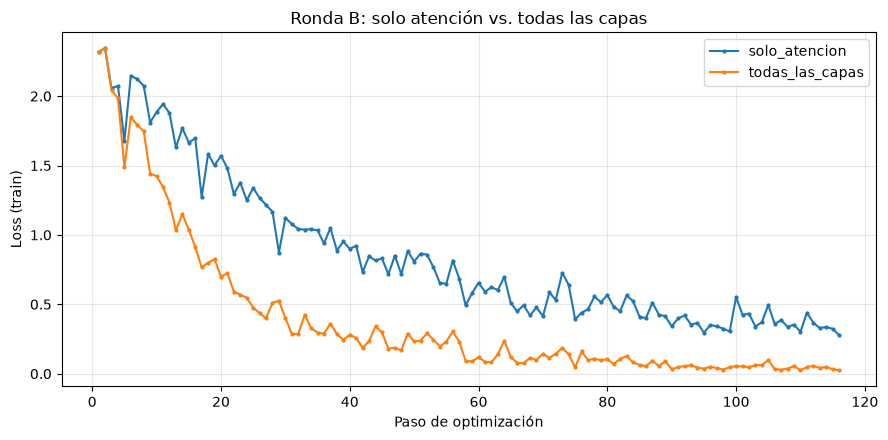

     capas_lora  parametros_entrenables  eval_loss_final  tiempo_min
todas_las_capas                30474240         0.596493        82.0
  solo_atencion                 3145728         0.724826        67.3


In [19]:
# Curvas de loss y comparación de la ronda B
plt.figure(figsize=(9, 4.5))
for nombre, r in resultados_ronda_b.items():
    plt.plot(r["train_steps"], r["train_loss"], marker="o", markersize=2, label=nombre)
plt.xlabel("Paso de optimización")
plt.ylabel("Loss (train)")
plt.title("Ronda B: solo atención vs. todas las capas")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

tabla_ronda_b = pd.DataFrame([
    {
        "capas_lora": nombre,
        "parametros_entrenables": r["entrenables"],
        "eval_loss_final": r["eval_loss_final"],
        "tiempo_min": round(r["tiempo_seg"] / 60, 1),
    }
    for nombre, r in resultados_ronda_b.items()
]).sort_values("eval_loss_final")
print(tabla_ronda_b.to_string(index=False))

## 7. Evaluación del mejor modelo contra el test set

El modelo con menor validation loss de las rondas A y B se evalúa contra el test set, que no se usó para elegir la configuración. Es el mismo modelo entrenado en los experimentos: no se vuelve a entrenar.

In [20]:
# Modelo con los pesos LoRA del mejor experimento y un trainer solo para evaluar
resultado_final = mejor_resultado
modelo_final = modelo
tokenizer_final = tokenizer
trainer_final = crear_trainer(resultado_final["config"], dataset_train_texto, dataset_val_texto, tag="_final")

print("Configuración final:", resultado_final["config"]["nombre"],
      f"({resultado_final['config']['epochs']} épocas)")
print(f"Eval loss final (validation): {resultado_final['eval_loss_final']:.4f}")

Configuración final: todas_las_capas (4 épocas)
Eval loss final (validation): 0.5965


In [21]:
# Evaluación final sobre el test set
metricas_test = trainer_final.evaluate(eval_dataset=dataset_test_texto)
print("Loss sobre el test set:", metricas_test["eval_loss"])

Unsloth: Tokenizing ["text"]: 100%|██████████| 57/57 [00:00<00:00, 386.58 examples/s]


Training Loss,Validation Loss,Epoch
No log,1.239616,0


Loss sobre el test set: 1.2396160364151


## 8. Comparación cualitativa: antes y después del fine-tuning

Se comparan las respuestas del mismo modelo con y sin los adaptadores LoRA. En las preguntas de investigación se espera que el modelo fine-tuned responda con el rol, el tono y las reglas del asistente descritos en el dossier. En las preguntas de control lo deseable no es una respuesta larga, sino que el modelo no pierda coherencia ni invente con seguridad información que no tiene.

In [22]:
# Mismo modelo con y sin adaptadores, sobre las mismas preguntas
FastLanguageModel.for_inference(modelo_final)

print("### Preguntas de negocio ###\n")
for pregunta in PREGUNTAS_INVESTIGACION:
    sin_lora = responder(modelo_final, tokenizer_final, pregunta, con_lora=False)
    con_lora = responder(modelo_final, tokenizer_final, pregunta, con_lora=True)
    print("PREGUNTA:", pregunta)
    print("SIN LoRA:", sin_lora)
    print("CON LoRA:", con_lora)
    print()

print("### Preguntas de control (generalización y olvido catastrófico) ###\n")
for pregunta in PREGUNTAS_CONTROL:
    sin_lora = responder(modelo_final, tokenizer_final, pregunta, con_lora=False)
    con_lora = responder(modelo_final, tokenizer_final, pregunta, con_lora=True)
    print("PREGUNTA:", pregunta)
    print("SIN LoRA:", sin_lora)
    print("CON LoRA:", con_lora)
    print()

### Preguntas de negocio ###

PREGUNTA: Qué es lo que puedes hacer para ayudarme en mi tesis?
SIN LoRA: ¡Excelente pregunta! Como modelo de inteligencia artificial, puedo actuar como un **asistente virtual especializado** a lo largo de todo el proceso de tu investigación. Aunque no puedo realizar la recolección de datos empírica ni escribir tu trabajo por ti (para mantener la integridad académica), sí puedo acelerar y mejorar significativamente cada etapa.

Aquí te detallo cómo puedo ayudarte específicamente:

### 1. Definición del Problema e Hipótesis
*   **Refinamiento:** Ayudarte a redactar una definición clara del problema de investigación basado en tus notas iniciales o borradores.
*   **Hipótesis:** Generar posibles hipótesis nulas alternativas basadas en teorías existentes o lógicas deductivas/inductivas.
*   **Delimitación:** Identificar qué aspectos incluir y cuáles excluir para evitar que el estudio sea demasiado amplio ("el problema de los límites").

### 2. Búsqueda y Sínte

Al leer las respuestas de arriba conviene revisar en concreto:

1. En la pregunta sobre qué puede hacer el asistente, si el modelo fine-tuned describe su rol (orientar en el acceso a bases de datos para investigación) en lugar de dar una respuesta genérica.
2. En la pregunta sobre las bases disponibles, si menciona el catálogo del dossier sin inventar bases que no existen.
3. En las preguntas de econometría y de teoría de juegos, que están fuera de su alcance, si las declina con cortesía y redirige a su función, como aprendió en los ejemplos de la categoría fuera de alcance, sin perder coherencia ni inventar contenido.

## 9. Guardar el modelo

Se guarda el **modelo completo mergeado** (Qwen3.5-4B + QLoRA fusionado, 16 bits) en `RUTA_LORA`,
**solo en modo no *thinking***, que es como se entrenó. Es el LLM que usará el RAG desde otro
script, cargándolo con `transformers` sin PEFT ni Unsloth.

`enable_thinking=False` en `plantilla_chat` solo vale dentro de este notebook: no queda guardado
en el modelo. Por eso, antes de guardar, se fija la plantilla de chat del tokenizer para que
siempre genere sin *thinking*, aunque el otro script no pase ese parámetro.

In [23]:
RUTA_LORA = r"..\output\LLMfine-tuning\LLM_Qlora"  # LLM completo (Qwen3.5-4B + LoRA)

# Plantilla de chat fija en modo no thinking (como en el entrenamiento), sin depender
# de que el script del RAG pase enable_thinking=False.
CONDICION_THINKING = "{%- if enable_thinking is defined and enable_thinking is false %}"
if CONDICION_THINKING not in tokenizer_final.chat_template:
    raise RuntimeError("No se encontró la condición de thinking en la plantilla de chat")
tokenizer_final.chat_template = tokenizer_final.chat_template.replace(CONDICION_THINKING, "{%- if true %}")

# Fusiona LoRA con los pesos base en 16 bits y guarda el modelo junto con el tokenizer.
modelo_final.save_pretrained_merged(
    RUTA_LORA,
    tokenizer_final,
    save_method="merged_16bit",
)
print("Modelo mergeado guardado en:", os.path.abspath(RUTA_LORA))

Unsloth: Restored added_tokens_decoder metadata in ..\output\LLMfine-tuning\LLM_Qlora\tokenizer_config.json.


Found HuggingFace hub cache directory: C:\Users\USER\.cache\huggingface\hub


Fetching 1 files: 100%|██████████| 1/1 [00:00<00:00, 28.70it/s]


Checking cache directory for required files...


Unsloth: Copying 2 files from cache to `..\output\LLMfine-tuning\LLM_Qlora`: 100%|██████████| 2/2 [00:12<00:00,  6.04s/it]


Successfully copied all 2 files from cache to `..\output\LLMfine-tuning\LLM_Qlora`
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [00:44<00:00, 22.42s/it]


Unsloth: Merge process complete. Saved to `c:\Users\USER\Dropbox\Personal_Desktop2026\RepositoryGitHub\RAGCentralDatabaseEconomy\output\LLMfine-tuning\LLM_Qlora`
Modelo mergeado guardado en: c:\Users\USER\Dropbox\Personal_Desktop2026\RepositoryGitHub\RAGCentralDatabaseEconomy\output\LLMfine-tuning\LLM_Qlora
